# A first model on an aligned series

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/01_first_model.ipynb)

This notebook fits a CMF 3D-QSAR model to a small aligned series, checks it by cross-validation,
draws the co-field that the model has learned, and splits one prediction over the atoms of a
molecule.

**What CMF is, in three sentences.** Every molecule is described by continuous fields, such as
its electrostatic potential or its steric bulk, each written as a sum of Gaussian functions
centred on the atoms. The similarity of two molecules is the overlap integral of their fields,
which has a closed form, and a kernel method (kernel ridge regression by default) fits the
activity from those similarities. The regression coefficients can be mapped back into space as a
*co-field*: a function whose positive regions are where the field raises the activity and whose
negative regions are where it lowers it.

The user manual (`docs/manual.md`) explains the method in *How a prediction is made* and the
program in *Building a model*; this notebook follows the library chapter, *Using it as a library*.

The data set is the classic steroid series with corticosteroid-binding globulin affinities
(`examples/steroids_cbg.sdf`): 31 aligned molecules, of which 21 form the published training set
and 10 the test set.

Running time: under a minute.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The data

The molecules are already aligned, so the file can be used as it is.

In [2]:
from cmfqsar import load_dataset

ds = load_dataset("examples/steroids_cbg.sdf", activity_prop="CBG_pK")
train_idx, test_idx = ds.train_indices, ds.test_indices
print(len(ds), "molecules:", len(train_idx), "training,", len(test_idx), "test")
print("activity range: %.2f to %.2f" % (ds.activity.min(), ds.activity.max()))

31 molecules: 21 training, 10 test
activity range: 5.00 to 7.88


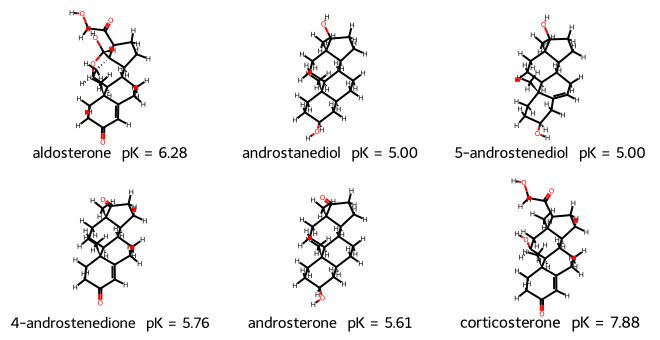

In [3]:
from rdkit.Chem import Draw

Draw.MolsToGridImage(ds.mols[:6], molsPerRow=3, subImgSize=(220, 170),
                     legends=["%s  pK = %.2f" % (n, a) for n, a in zip(ds.names[:6], ds.activity[:6])])

## The fields

`FieldSet.create()` gives the default physico-chemical fields: electrostatic, steric,
hydrophobic, hydrogen-bond acceptor and donor. `build_fields` turns each molecule into a set of
Gaussians, one per atom and field, and `AtomTable` stacks the training molecules into the arrays
the kernel is computed from.

In [4]:
from cmfqsar import FieldSet
from cmfqsar.fields import AtomTable, build_fields

fs = FieldSet.create()
print("fields:", fs.names)
mf = [build_fields(m, fs, n) for m, n in zip(ds.mols, ds.names)]
train = AtomTable.from_molecules([mf[i] for i in train_idx])
test = AtomTable.from_molecules([mf[i] for i in test_idx])
print(train.n_mol, "training molecules,", len(train.coords), "atoms")

fields: ['electrostatic', 'steric', 'hydrophobic', 'hba', 'hbd']


21 training molecules, 1079 atoms


## Fitting

Two parameters are chosen by cross-validation: the attenuation factor *alpha*, which sets the
width of the Gaussians and so how local the similarity is, and the regularisation *lambda*.
`grid_search` tries every pair and leaves the best one in the model; `fit` then fits the model
on all training molecules and reports the fit and the ten-fold cross-validation.

In [5]:
from cmfqsar import CMFModel
from cmfqsar.model import grid_search

model = CMFModel(fieldset=fs, method="krr", normalize=True)
res = grid_search(train, ds.activity[train_idx], model, alphas=[0.5, 1.0, 2.0, 3.0, 4.0],
                  lams=[1e-3, 1e-2, 0.1, 1.0])
print("chosen alpha =", res.best_alpha, " lambda =", model.params["lam"])
print("\nbest q2 at each alpha (over the four lambdas):")
for a in sorted({row["alpha"] for row in res.table}):
    print("  alpha %4.1f   q2 %.3f" % (a, max(row["q2"] for row in res.table if row["alpha"] == a)))
model.fit(train, ds.activity[train_idx], cv_folds=10)
print(model.stats.summary())

chosen alpha = 4.0  lambda = 1.0

best q2 at each alpha (over the four lambdas):
  alpha  0.5   q2 0.780
  alpha  1.0   q2 0.791
  alpha  2.0   q2 0.801
  alpha  3.0   q2 0.811
  alpha  4.0   q2 0.821
Training set: n = 21
  r2 (fit)        = 0.949    RMSE (fit)  = 0.259
  q2 (10-fold CV)  = 0.821    RMSEcv      = 0.485


The cross-validated score changes little across the attenuation grid: the surface is flat around
its optimum, which is usual for CMF models, so the exact value chosen matters less than it
seems and a value at the edge of the grid is not a reason to keep extending it.

`q2` is the cross-validated determination coefficient: the share of the variance of the
activities that the model predicts for molecules it did not see during each fold. It is the
number to judge a model by, not `r2` of the fit. The test set is the second check.

test set: R2pred = 0.564, RMSE = 0.634


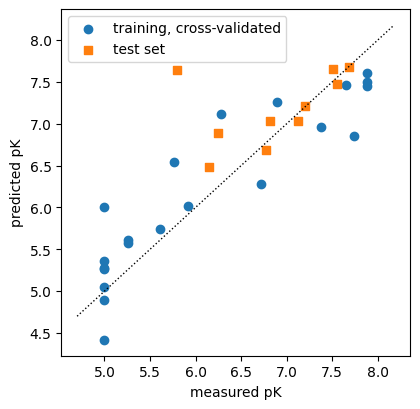

In [6]:
import numpy as np
import matplotlib.pyplot as plt

y_tr, y_te = ds.activity[train_idx], ds.activity[test_idx]
y_cv = model.stats.extra["y_cv"]
y_pred = model.predict(test)
r2_pred = 1 - np.sum((y_te - y_pred) ** 2) / np.sum((y_te - y_tr.mean()) ** 2)
print("test set: R2pred = %.3f, RMSE = %.3f" % (r2_pred, np.sqrt(np.mean((y_te - y_pred) ** 2))))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(y_tr, y_cv, label="training, cross-validated")
ax.scatter(y_te, y_pred, marker="s", label="test set")
lo, hi = ds.activity.min() - 0.3, ds.activity.max() + 0.3
ax.plot([lo, hi], [lo, hi], "k:", lw=1)
ax.set_xlabel("measured pK"); ax.set_ylabel("predicted pK"); ax.legend(); plt.show()

## The co-field

The co-field of a field type is the map of its regression coefficients in space. Where it is
positive, more of that field raises the activity; where it is negative, more of it lowers the
activity. It is evaluated on a grid around the training molecules and written as a Gaussian cube
file, which any molecular viewer can read; here py3Dmol draws it inside the notebook around the
most active molecule. Blue is positive, red negative.

In [7]:
def view_molecule(molblock, cube_text=None, level=None, size=(600, 420)):
    """A 3D view of one molecule, with the positive and negative lobes of a volume if given."""
    try:
        import py3Dmol
    except ImportError:
        print("py3Dmol is not installed (pip install py3Dmol); the 3D view is skipped")
        return None
    v = py3Dmol.view(width=size[0], height=size[1])
    v.addModel(molblock, "mol")
    v.setStyle({"stick": {"radius": 0.15}, "sphere": {"scale": 0.22}})
    if cube_text is not None:
        v.addVolumetricData(cube_text, "cube", {"isoval": level, "color": "blue", "opacity": 0.75})
        v.addVolumetricData(cube_text, "cube", {"isoval": -level, "color": "red", "opacity": 0.75})
    v.zoomTo()
    return v.show()

In [8]:
import tempfile, os
from cmfqsar.cofields import make_grid, cofield_volume, export_cube

f = fs.names.index("steric")
grid = make_grid(train.coords, margin=3.0, spacing=0.75)
volume = cofield_volume(model, f, grid)
level = 0.35 * np.abs(volume).max()
print("co-field of the %s field on %d grid points; drawn at +/- %.3g" % (fs.names[f], grid.n_points, level))

best = int(np.argmax(y_tr))
cube_path = os.path.join(tempfile.gettempdir(), "cofield_steric.cube")
export_cube(cube_path, grid, volume, mf[train_idx[best]])
with open(cube_path) as fh:
    cube_text = fh.read()
view_molecule(mf[train_idx[best]].molblock, cube_text, level)

co-field of the steric field on 9450 grid points; drawn at +/- 0.0172


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

The steric co-field says where bulk helps binding and where it hurts. The same call with the
index of another field, for example `fs.names.index("electrostatic")`, gives that field's
co-field; the manual's chapter *Reading the model* explains how to read them together and how
their reliability is judged.

## Which atoms make the prediction

For the linear kernel a prediction is a sum over the atoms of the molecule, so each atom's share
can be reported. The table below lists the atoms of the most active training molecule with the
largest contributions, positive or negative.

In [9]:
m = mf[train_idx[best]]
contrib = model.atom_contributions(m)
order = np.argsort(-np.abs(contrib))[:10]
print("%-5s %-6s %10s" % ("atom", "symbol", "share"))
for i in order:
    print("%-5d %-6s %10.3f" % (i + 1, m.symbols[i], contrib[i]))
print("sum over all atoms + bias = %.3f, predicted = %.3f" % (contrib.sum() + model.bias, model.predict(AtomTable.from_molecules([m]))[0]))

atom  symbol      share
15    O           0.422
32    H           0.289
22    O           0.272
30    H           0.253
24    O           0.235
17    O           0.119
21    C           0.052
1     C           0.049
23    C           0.027
51    H           0.016
sum over all atoms + bias = 7.657, predicted = 7.657


## The same model from the command line

Everything above is one command in the command-line tool, which also writes the co-fields and a
report:

```
cmf build examples/steroids_cbg.sdf --activity CBG_pK --alphas 0.3,0.5,1,2 --save steroids.cmf
```

The next notebook, *A series with no alignment*, takes a table of SMILES, where no common frame
exists, and uses the rotation-invariant kernel instead.